<a href="https://colab.research.google.com/github/devitanuraljazira/Model-ML-DL/blob/main/USP5_tanimoto_80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SVR Tanimoto-kernel tunggal

In [1]:
!pip install -q rdkit scikit-learn scipy pandas numpy matplotlib seaborn xgboost lightgbm

In [2]:
import sys
import torch
import rdkit
import sklearn
import pandas as pd
import numpy as np

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("RDKit:", rdkit.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch: 2.14.1+cpu
RDKit: 2026.09.2
Scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3


In [3]:
import pandas as pd
import numpy as np

CSV_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/Model-ML-DL/refs/heads/main/"
    "USP5_Kd_80_fixed.csv"
)

df = pd.read_csv(CSV_URL)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (80, 3)
Columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
3,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
4,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373


In [4]:
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")

df["mol"] = df["Smiles"].apply(Chem.MolFromSmiles)

print("Total compounds:", len(df))
print("Valid SMILES:", df["mol"].notna().sum())
print("Unique SMILES:", df["Smiles"].nunique())
print("Missing pKd:", df["pKd"].isna().sum())

assert len(df) == 80
assert df["mol"].notna().all()
assert df["pKd"].notna().all()

Total compounds: 80
Valid SMILES: 80
Unique SMILES: 80
Missing pKd: 0


In [5]:
from rdkit.Chem import rdFingerprintGenerator, MACCSkeys

# Morgan fingerprint
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

FP = np.array([
    generator.GetFingerprintAsNumPy(mol)
    for mol in df["mol"]
], dtype=np.uint8)

# MACCS fingerprint
MACCS = np.array([
    np.array(MACCSkeys.GenMACCSKeys(mol))
    for mol in df["mol"]
], dtype=np.uint8)

# Combine fingerprints
X_FPM = np.hstack([FP, MACCS])

y = df["pKd"].to_numpy(dtype=float)

print("Morgan:", FP.shape)
print("MACCS:", MACCS.shape)
print("Combined:", X_FPM.shape)
print("Target:", y.shape)

Morgan: (80, 1024)
MACCS: (80, 167)
Combined: (80, 1191)
Target: (80,)


In [6]:
def tanimoto_kernel(X, Y):
    intersection = X @ Y.T

    sum_X = X.sum(axis=1)[:, None]
    sum_Y = Y.sum(axis=1)[None, :]

    union = sum_X + sum_Y - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection, dtype=float),
        where=union != 0
    )

K = tanimoto_kernel(X_FPM, X_FPM)

print("Kernel shape:", K.shape)
print("Minimum:", K.min())
print("Maximum:", K.max())
print("Symmetric:", np.allclose(K, K.T))

Kernel shape: (80, 80)
Minimum: 0.13725490196078433
Maximum: 1.0
Symmetric: True


In [7]:
def tanimoto_kernel(X, Y):
    X = X.astype(np.int32)
    Y = Y.astype(np.int32)

    intersection = X @ Y.T

    sum_X = X.sum(axis=1)[:, None]
    sum_Y = Y.sum(axis=1)[None, :]

    union = sum_X + sum_Y - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection, dtype=float),
        where=union != 0
    )

K = tanimoto_kernel(X_FPM, X_FPM)

In [8]:
from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.base import clone

models = {
    "SVR_Tanimoto": SVR(
        kernel="precomputed",
        C=5.0
    ),

    "KRR_Tanimoto": KernelRidge(
        alpha=0.2,
        kernel="precomputed"
    )
}

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
oof_predictions = {}

for name, model in models.items():

    oof = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(
        kf.split(X_FPM), start=1
    ):

        K_train = K[np.ix_(train_idx, train_idx)]
        K_test = K[np.ix_(test_idx, train_idx)]

        model.fit(K_train, y[train_idx])

        pred = model.predict(K_test)

        oof[test_idx] = pred

        print(
            f"{name} | Fold {fold} | "
            f"RMSE: {mean_squared_error(y[test_idx], pred)**0.5:.4f}"
        )

    rmse = mean_squared_error(y, oof)**0.5
    mae = mean_absolute_error(y, oof)
    r2 = r2_score(y, oof)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    oof_predictions[name] = oof

results_df = pd.DataFrame(results)

display(results_df.round(4))

SVR_Tanimoto | Fold 1 | RMSE: 0.3050
SVR_Tanimoto | Fold 2 | RMSE: 0.2904
SVR_Tanimoto | Fold 3 | RMSE: 0.5171
SVR_Tanimoto | Fold 4 | RMSE: 0.3628
SVR_Tanimoto | Fold 5 | RMSE: 0.2807
KRR_Tanimoto | Fold 1 | RMSE: 0.2396
KRR_Tanimoto | Fold 2 | RMSE: 0.3592
KRR_Tanimoto | Fold 3 | RMSE: 0.6344
KRR_Tanimoto | Fold 4 | RMSE: 0.4326
KRR_Tanimoto | Fold 5 | RMSE: 0.5341


,Model,RMSE,MAE,R2
0,SVR_Tanimoto,0.3620,0.2763,0.6722
1,KRR_Tanimoto,0.4607,0.3096,0.4690


In [9]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupKFold

df["scaffold"] = df["mol"].apply(
    lambda mol: MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )
)

groups = df["scaffold"].to_numpy()

print("Unique scaffolds:", len(set(groups)))

Unique scaffolds: 38


In [10]:
gkf = GroupKFold(n_splits=5)

scaffold_results = []

for name, model in models.items():

    oof = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(X_FPM, y, groups), start=1
    ):

        K_train = K[np.ix_(train_idx, train_idx)]
        K_test = K[np.ix_(test_idx, train_idx)]

        model.fit(K_train, y[train_idx])

        pred = model.predict(K_test)

        oof[test_idx] = pred

        print(
            f"{name} | Scaffold Fold {fold} | "
            f"RMSE: {mean_squared_error(y[test_idx], pred)**0.5:.4f}"
        )

    scaffold_results.append({
        "Model": name,
        "RMSE": mean_squared_error(y, oof)**0.5,
        "MAE": mean_absolute_error(y, oof),
        "R2": r2_score(y, oof)
    })

    oof_predictions[name + "_scaffold"] = oof

scaffold_results_df = pd.DataFrame(scaffold_results)

display(scaffold_results_df.round(4))

SVR_Tanimoto | Scaffold Fold 1 | RMSE: 0.3076
SVR_Tanimoto | Scaffold Fold 2 | RMSE: 0.3016
SVR_Tanimoto | Scaffold Fold 3 | RMSE: 0.5110
SVR_Tanimoto | Scaffold Fold 4 | RMSE: 0.6185
SVR_Tanimoto | Scaffold Fold 5 | RMSE: 0.3018
KRR_Tanimoto | Scaffold Fold 1 | RMSE: 0.3363
KRR_Tanimoto | Scaffold Fold 2 | RMSE: 0.5287
KRR_Tanimoto | Scaffold Fold 3 | RMSE: 0.6888
KRR_Tanimoto | Scaffold Fold 4 | RMSE: 0.8830
KRR_Tanimoto | Scaffold Fold 5 | RMSE: 0.3319


,Model,RMSE,MAE,R2
0,SVR_Tanimoto,0.4158,0.3054,0.5676
1,KRR_Tanimoto,0.5689,0.3854,0.1903


In [11]:
results_df.to_csv(
    "Tanimoto_Random_5Fold_Results.csv",
    index=False
)

scaffold_results_df.to_csv(
    "Tanimoto_Scaffold_5Fold_Results.csv",
    index=False
)

predictions = df[
    ["Molecule ChEMBL ID", "Smiles", "pKd"]
].copy()

for name, pred in oof_predictions.items():
    predictions[name] = pred

predictions.to_csv(
    "Tanimoto_OOF_Predictions.csv",
    index=False
)

print("All results saved successfully!")

All results saved successfully!


In [12]:
from google.colab import files

files.download("Tanimoto_Random_5Fold_Results.csv")
files.download("Tanimoto_Scaffold_5Fold_Results.csv")
files.download("Tanimoto_OOF_Predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

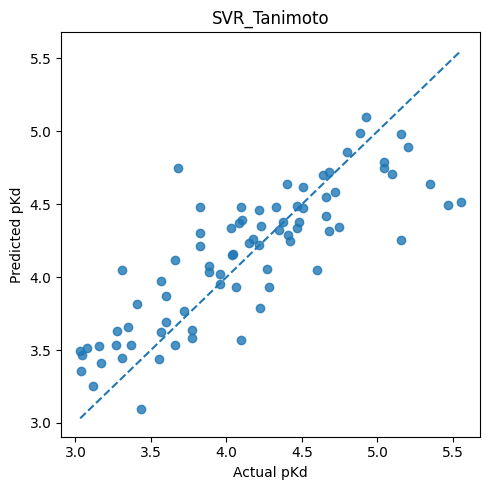

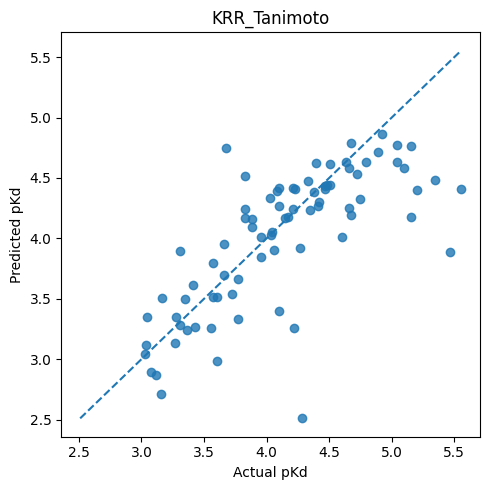

In [13]:
import matplotlib.pyplot as plt

for name, pred in oof_predictions.items():

    if "_scaffold" in name:
        continue

    plt.figure(figsize=(5, 5))

    plt.scatter(y, pred, alpha=0.8)

    low = min(y.min(), pred.min())
    high = max(y.max(), pred.max())

    plt.plot(
        [low, high],
        [low, high],
        linestyle="--"
    )

    plt.xlabel("Actual pKd")
    plt.ylabel("Predicted pKd")
    plt.title(name)

    plt.tight_layout()
    plt.show()

Tanimoto blend-
1.   SVR dengan Tanimoto Kernel.
2.   Random Forest menggunakan Morgan Fingerprint + MACCS.
3.   Random Forest menggunakan MACCS Fingerprint.

In [31]:

!pip install -q rdkit scikit-learn scipy xgboost lightgbm


In [32]:

import sys
import os
import warnings
import pickle

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import (
    Descriptors,
    rdFingerprintGenerator,
    MACCSkeys
)
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from scipy.stats import pearsonr, spearmanr

RDLogger.DisableLog("rdApp.*")

RANDOM_STATE = 0

import rdkit
import sklearn

print("Python:", sys.version.split()[0])
print("RDKit:", rdkit.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nEnvironment ready!")


Python: 3.13.18
RDKit: 2026.09.2
Scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3

Environment ready!


In [33]:

CSV_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/Model-ML-DL/refs/heads/main/"
    "USP5_Kd_80_fixed.csv"
)

LOCAL = "USP5_Kd_80_fixed.csv"

df = pd.read_csv(CSV_URL)

df.columns = df.columns.str.strip()

df["mol"] = df["Smiles"].apply(Chem.MolFromSmiles)

assert len(df) == 80, "Dataset must contain 80 compounds"
assert df["mol"].notna().all(), "Invalid SMILES detected"
assert df["pKd"].notna().all(), "Missing pKd values"

df["scaffold"] = df["mol"].apply(
    lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m)
)

y = df["pKd"].to_numpy(dtype=float)

groups = df["scaffold"].to_numpy()

print("Number of compounds:", len(df))
print("Unique SMILES:", df["Smiles"].nunique())
print("Unique scaffolds:", df["scaffold"].nunique())

print(
    f"pKd min / median / max: "
    f"{y.min():.3f} / {np.median(y):.3f} / {y.max():.3f}"
)

print(
    f"pKd mean ± SD: "
    f"{y.mean():.3f} ± {y.std(ddof=1):.3f}"
)

display(
    df[
        ["Molecule ChEMBL ID", "Smiles", "pKd", "scaffold"]
    ].head()
)


Number of compounds: 80
Unique SMILES: 80
Unique scaffolds: 38
pKd min / median / max: 3.032 / 4.100 / 5.553
pKd mean ± SD: 4.121 ± 0.636


,Molecule ChEMBL ID,Smiles,pKd,scaffold
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057,O=C1Cc2ccccc2N1C1CCN(S(=O)(=O)c2ccccc2)CC1
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787,c1ccc(-c2nnco2)cc1
2,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787,O=S(=O)(c1ccccc1)N1CCC(N2CCOCC2)CC1
3,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1
4,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1


In [34]:

# ==========================================
# STEP 5: MOLECULAR FEATURIZATION
# ==========================================

def build_descriptors(mols, corr_cut=0.95):

    names = [n for n, _ in Descriptors._descList]
    rows = []

    for mol in mols:
        vals = []

        for _, fn in Descriptors._descList:
            try:
                vals.append(fn(mol))
            except Exception:
                vals.append(np.nan)

        rows.append(vals)

    Xd = pd.DataFrame(rows, columns=names)

    Xd = Xd.replace(
        [np.inf, -np.inf], np.nan
    )

    n0 = Xd.shape[1]

    Xd = Xd.loc[:, Xd.isna().sum() == 0]
    n1 = Xd.shape[1]

    Xd = Xd.loc[:, Xd.std() > 0]
    n2 = Xd.shape[1]

    corr = Xd.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )

    drop = [
        col for col in upper.columns
        if (upper[col] > corr_cut).any()
    ]

    Xd = Xd.drop(columns=drop)

    print(
        f"Descriptors: {n0} raw -> "
        f"{n1} without NaN -> "
        f"{n2} non-zero variance -> "
        f"{Xd.shape[1]} after correlation filtering"
    )

    return Xd


def build_morgan(
    mols,
    radius=2,
    nbits=1024,
    min_count=4
):

    gen = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=nbits
    )

    F = np.array([
        gen.GetFingerprintAsNumPy(mol)
        for mol in mols
    ], dtype=float)

    mask = (F > 0).sum(axis=0) >= min_count

    print(
        f"Morgan r={radius}: {nbits} bits -> "
        f"{int(mask.sum())} selected bits"
    )

    return F[:, mask], mask


def build_maccs(mols):

    K = np.array([
        np.array(MACCSkeys.GenMACCSKeys(mol))
        for mol in mols
    ], dtype=float)

    mask = K.std(axis=0) > 0

    print(
        f"MACCS: 167 keys -> "
        f"{int(mask.sum())} informative keys"
    )

    return K[:, mask], mask


# Generate descriptors
DESC_df = build_descriptors(df["mol"])

# Generate Morgan fingerprint
FP, FP_MASK = build_morgan(df["mol"])

# Generate MACCS fingerprint
MACCS, MACCS_MASK = build_maccs(df["mol"])

# Combine features
X_DESC = DESC_df.to_numpy()

X_FPM = np.hstack([FP, MACCS])

X_ALL = np.hstack([X_DESC, FP, MACCS])

# Organize feature blocks
BLOCKS = {
    "DESC": X_DESC,
    "FP": FP,
    "MACCS": MACCS,
    "FPM": X_FPM,
    "ALL": X_ALL
}

print("\nFINAL FEATURE DIMENSIONS")

for name, matrix in BLOCKS.items():
    print(f"{name:8s}: {matrix.shape}")


Descriptors: 217 raw -> 209 without NaN -> 150 non-zero variance -> 108 after correlation filtering
Morgan r=2: 1024 bits -> 137 selected bits
MACCS: 167 keys -> 121 informative keys

FINAL FEATURE DIMENSIONS
DESC    : (80, 108)
FP      : (80, 137)
MACCS   : (80, 121)
FPM     : (80, 258)
ALL     : (80, 366)


In [35]:

# ==========================================
# STEP 6: TANIMOTO KERNEL
# ==========================================

def tanimoto_kernel(A, B):

    inter = A @ B.T

    a = (A * A).sum(axis=1)[:, None]
    b = (B * B).sum(axis=1)[None, :]

    return inter / (a + b - inter + 1e-12)


# Calculate kernel matrix
K = tanimoto_kernel(X_FPM, X_FPM)

print("Kernel matrix:", K.shape)
print("Minimum:", K.min())
print("Maximum:", K.max())
print("Symmetric:", np.allclose(K, K.T))

# Check positive semi-definite
eig = np.linalg.eigvalsh(K)

print("Minimum eigenvalue:", eig.min())


Kernel matrix: (80, 80)
Minimum: 0.11290322580645071
Maximum: 0.9999999999999916
Symmetric: True
Minimum eigenvalue: 0.006634609877078265


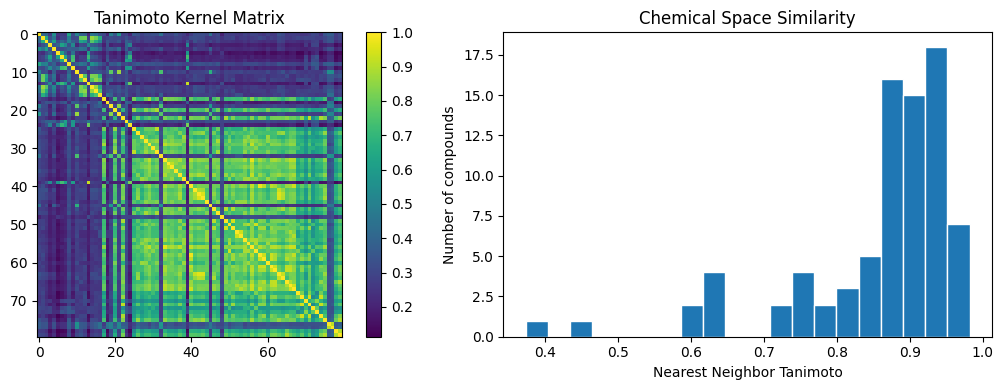

Mean nearest-neighbor similarity: 0.8558061910996916


In [36]:

Koff = K.copy()
np.fill_diagonal(Koff, 0.0)

nn_sim = Koff.max(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

im = ax[0].imshow(
    K[np.argsort(y)][:, np.argsort(y)],
    cmap="viridis"
)

ax[0].set_title("Tanimoto Kernel Matrix")
plt.colorbar(im, ax=ax[0])

ax[1].hist(
    nn_sim,
    bins=20,
    edgecolor="white"
)

ax[1].set_xlabel("Nearest Neighbor Tanimoto")
ax[1].set_ylabel("Number of compounds")
ax[1].set_title("Chemical Space Similarity")

plt.tight_layout()
plt.show()

print("Mean nearest-neighbor similarity:", nn_sim.mean())


In [37]:

# ==========================================
# STEP 8: SVR TANIMOTO MODEL
# ==========================================

from sklearn.base import BaseEstimator, RegressorMixin

class TanimotoSVR(BaseEstimator, RegressorMixin):

    def __init__(self, C=5.0, epsilon=0.05):
        self.C = C
        self.epsilon = epsilon

    def fit(self, X, yy):

        self.X_ = X

        self.model_ = SVR(
            kernel="precomputed",
            C=self.C,
            epsilon=self.epsilon
        )

        K_train = tanimoto_kernel(X, X)

        self.model_.fit(K_train, yy)

        return self

    def predict(self, X):

        K_test = tanimoto_kernel(X, self.X_)

        return self.model_.predict(K_test)


svr_model = TanimotoSVR(C=5.0, epsilon=0.05)

print("SVR Tanimoto model initialized!")


SVR Tanimoto model initialized!


In [39]:

# ==========================================
# STEP 9: CROSS VALIDATION FUNCTIONS
# ==========================================

def folds_random(seed):
    return list(
        KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        ).split(np.arange(len(y)))
    )


def folds_scaffold(seed):

    unique_groups = np.unique(groups)

    perm = np.random.RandomState(seed).permutation(
        len(unique_groups)
    )

    group_map = {
        g: perm[i] % 5
        for i, g in enumerate(unique_groups)
    }

    fold_assignment = np.array([
        group_map[g] for g in groups
    ])

    return [
        (
            np.where(fold_assignment != k)[0],
            np.where(fold_assignment == k)[0]
        )
        for k in range(5)
        if (fold_assignment == k).sum() > 0
    ]


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(y_true, y_pred)
    }


def oof_svr(fold_list):

    oof = np.zeros(len(y))

    for train_idx, test_idx in fold_list:

        model = TanimotoSVR(
            C=5.0,
            epsilon=0.05
        )

        model.fit(
            X_FPM[train_idx],
            y[train_idx]
        )

        oof[test_idx] = model.predict(
            X_FPM[test_idx]
        )

    return oof


In [40]:

SEEDS_SEL_RAND = [100, 101, 102, 103, 104]

svr_random_results = []

for seed in SEEDS_SEL_RAND:

    pred = oof_svr(folds_random(seed))

    result = calculate_metrics(y, pred)

    result["Seed"] = seed

    svr_random_results.append(result)

svr_random_df = pd.DataFrame(svr_random_results)

display(svr_random_df.round(4))

print("\nMean ± SD")

display(
    svr_random_df[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)


,R2,RMSE,MAE,Seed
0,0.6320,0.3835,0.2786,100
1,0.7251,0.3315,0.2563,101
2,0.7372,0.3241,0.2509,102
3,0.7222,0.3332,0.2629,103
4,0.6873,0.3535,0.2744,104



Mean ± SD


,R2,RMSE,MAE
mean,0.7008,0.3452,0.2646
std,0.0427,0.0241,0.0117


In [41]:

SEEDS_SEL_SCAF = [200, 201, 202, 203, 204]

svr_scaffold_results = []

for seed in SEEDS_SEL_SCAF:

    pred = oof_svr(folds_scaffold(seed))

    result = calculate_metrics(y, pred)

    result["Seed"] = seed

    svr_scaffold_results.append(result)

svr_scaffold_df = pd.DataFrame(svr_scaffold_results)

display(svr_scaffold_df.round(4))

print("\nMean ± SD")

display(
    svr_scaffold_df[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)


,R2,RMSE,MAE,Seed
0,0.5673,0.4159,0.3128,200
1,0.5443,0.4268,0.3236,201
2,0.6020,0.3989,0.3045,202
3,0.4975,0.4482,0.3322,203
4,0.3740,0.5003,0.3789,204



Mean ± SD


,R2,RMSE,MAE
mean,0.5170,0.4380,0.3304
std,0.0885,0.0391,0.0291


In [42]:

# ==========================================
# STEP 10: RANDOM FOREST FPM
# ==========================================

def create_rf_model():
    return RandomForestRegressor(
        n_estimators=300,
        random_state=0,
        n_jobs=-1
    )


def oof_rf(X, fold_list):

    oof = np.zeros(len(y))

    for train_idx, test_idx in fold_list:

        model = create_rf_model()

        model.fit(
            X[train_idx],
            y[train_idx]
        )

        oof[test_idx] = model.predict(
            X[test_idx]
        )

    return oof


print("Random Forest FPM initialized")
print("Input dimensions:", X_FPM.shape)


Random Forest FPM initialized
Input dimensions: (80, 258)


In [43]:

# ==========================================
# RF FPM: RANDOM 5-FOLD CV
# ==========================================

rf_fpm_random_results = []

for seed in SEEDS_SEL_RAND:

    pred = oof_rf(
        X_FPM,
        folds_random(seed)
    )

    result = calculate_metrics(y, pred)
    result["Seed"] = seed

    rf_fpm_random_results.append(result)

rf_fpm_random_df = pd.DataFrame(
    rf_fpm_random_results
)

display(rf_fpm_random_df.round(4))

print("\nMean ± SD")

display(
    rf_fpm_random_df[
        ["R2", "RMSE", "MAE"]
    ].agg(["mean", "std"]).round(4)
)


,R2,RMSE,MAE,Seed
0,0.6697,0.3634,0.2738,100
1,0.7210,0.3340,0.2563,101
2,0.6928,0.3505,0.2761,102
3,0.7064,0.3426,0.2652,103
4,0.6971,0.3480,0.2682,104



Mean ± SD


,R2,RMSE,MAE
mean,0.6974,0.3477,0.2679
std,0.0189,0.0108,0.0078


In [44]:

# ==========================================
# RF FPM: SCAFFOLD 5-FOLD CV
# ==========================================

rf_fpm_scaffold_results = []

for seed in SEEDS_SEL_SCAF:

    pred = oof_rf(
        X_FPM,
        folds_scaffold(seed)
    )

    result = calculate_metrics(y, pred)
    result["Seed"] = seed

    rf_fpm_scaffold_results.append(result)

rf_fpm_scaffold_df = pd.DataFrame(
    rf_fpm_scaffold_results
)

display(rf_fpm_scaffold_df.round(4))

print("\nMean ± SD")

display(
    rf_fpm_scaffold_df[
        ["R2", "RMSE", "MAE"]
    ].agg(["mean", "std"]).round(4)
)


,R2,RMSE,MAE,Seed
0,0.6015,0.3991,0.3122,200
1,0.5815,0.4090,0.3220,201
2,0.6589,0.3693,0.2866,202
3,0.6081,0.3958,0.3069,203
4,0.5168,0.4395,0.3370,204



Mean ± SD


,R2,RMSE,MAE
mean,0.5934,0.4025,0.3129
std,0.0514,0.0253,0.0186


In [45]:

# ==========================================
# STEP 11: RANDOM FOREST MACCS
# ==========================================

rf_maccs_random_results = []

for seed in SEEDS_SEL_RAND:

    pred = oof_rf(
        MACCS,
        folds_random(seed)
    )

    result = calculate_metrics(y, pred)
    result["Seed"] = seed

    rf_maccs_random_results.append(result)

rf_maccs_random_df = pd.DataFrame(
    rf_maccs_random_results
)

display(rf_maccs_random_df.round(4))

print("\nMean ± SD")

display(
    rf_maccs_random_df[
        ["R2", "RMSE", "MAE"]
    ].agg(["mean", "std"]).round(4)
)


,R2,RMSE,MAE,Seed
0,0.6369,0.3810,0.2834,100
1,0.6548,0.3715,0.2806,101
2,0.6649,0.3660,0.2809,102
3,0.6879,0.3532,0.2727,103
4,0.6326,0.3833,0.2956,104



Mean ± SD


,R2,RMSE,MAE
mean,0.6554,0.3710,0.2826
std,0.0224,0.0122,0.0083


In [46]:

# ==========================================
# RF MACCS: SCAFFOLD 5-FOLD CV
# ==========================================

rf_maccs_scaffold_results = []

for seed in SEEDS_SEL_SCAF:

    pred = oof_rf(
        MACCS,
        folds_scaffold(seed)
    )

    result = calculate_metrics(y, pred)
    result["Seed"] = seed

    rf_maccs_scaffold_results.append(result)

rf_maccs_scaffold_df = pd.DataFrame(
    rf_maccs_scaffold_results
)

display(rf_maccs_scaffold_df.round(4))

print("\nMean ± SD")

display(
    rf_maccs_scaffold_df[
        ["R2", "RMSE", "MAE"]
    ].agg(["mean", "std"]).round(4)
)


,R2,RMSE,MAE,Seed
0,0.6377,0.3805,0.2883,200
1,0.6338,0.3826,0.3012,201
2,0.6210,0.3893,0.2972,202
3,0.6228,0.3883,0.2983,203
4,0.4172,0.4827,0.3481,204



Mean ± SD


,R2,RMSE,MAE
mean,0.5865,0.4047,0.3066
std,0.0949,0.0438,0.0237


In [47]:

# ==========================================
# STEP 10: TANIMOTO BLEND INPUT
# ==========================================

X_BLEND = np.hstack([X_FPM, MACCS])

N_FPM = X_FPM.shape[1]

print("X_BLEND:", X_BLEND.shape)
print("FPM features:", N_FPM)
print("MACCS features:", MACCS.shape[1])

assert X_BLEND.shape == (80, 379)

print("Tanimoto Blend input ready!")


X_BLEND: (80, 379)
FPM features: 258
MACCS features: 121
Tanimoto Blend input ready!


In [48]:

# ==========================================
# STEP 11: TANIMOTO BLEND MODEL
# ==========================================

class TanimotoBlend(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        n_fpm,
        C=5.0,
        epsilon=0.05,
        n_estimators=300,
        calibrate=False,
        random_state=0
    ):

        self.n_fpm = n_fpm
        self.C = C
        self.epsilon = epsilon
        self.n_estimators = n_estimators
        self.calibrate = calibrate
        self.random_state = random_state

    def _views(self, X):

        return X[:, :self.n_fpm], X[:, self.n_fpm:]

    def fit(self, X, yy):

        F, M = self._views(X)

        self.F_ = F

        # Model 1: SVR Tanimoto
        self.svr_ = SVR(
            kernel="precomputed",
            C=self.C,
            epsilon=self.epsilon
        ).fit(
            tanimoto_kernel(F, F),
            yy
        )

        # Model 2: Random Forest FPM
        self.rf_fpm_ = RandomForestRegressor(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=-1
        ).fit(F, yy)

        # Model 3: Random Forest MACCS
        self.rf_maccs_ = RandomForestRegressor(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=-1
        ).fit(M, yy)

        self.a_, self.b_ = 1.0, 0.0

        # Optional nested calibration
        if self.calibrate:

            o = np.zeros(len(yy))

            for tr, te in KFold(
                5,
                shuffle=True,
                random_state=self.random_state
            ).split(X):

                inner = TanimotoBlend(
                    self.n_fpm,
                    self.C,
                    self.epsilon,
                    self.n_estimators,
                    calibrate=False,
                    random_state=self.random_state
                ).fit(X[tr], yy[tr])

                o[te] = inner.predict(X[te])

            self.a_, self.b_ = np.polyfit(o, yy, 1)

        return self

    def predict_members(self, X):

        F, M = self._views(X)

        return {
            "SVR-Tanimoto": self.svr_.predict(
                tanimoto_kernel(F, self.F_)
            ),

            "RF-FPM": self.rf_fpm_.predict(F),

            "RF-MACCS": self.rf_maccs_.predict(M)
        }

    def predict(self, X):

        predictions = self.predict_members(X)

        p = np.mean(
            list(predictions.values()),
            axis=0
        )

        return self.a_ * p + self.b_


print("Tanimoto Blend model initialized!")


Tanimoto Blend model initialized!


In [49]:

# ==========================================
# STEP 12: BLEND OOF PREDICTIONS
# ==========================================

def blend_oof(
    fold_list,
    calibrate=False,
    return_members=False
):

    o = np.zeros(len(y))

    members = {
        "SVR-Tanimoto": np.zeros(len(y)),
        "RF-FPM": np.zeros(len(y)),
        "RF-MACCS": np.zeros(len(y))
    }

    for tr, te in fold_list:

        model = TanimotoBlend(
            n_fpm=N_FPM,
            calibrate=calibrate
        )

        model.fit(
            X_BLEND[tr],
            y[tr]
        )

        o[te] = model.predict(X_BLEND[te])

        if return_members:

            member_predictions = model.predict_members(
                X_BLEND[te]
            )

            for name, pred in member_predictions.items():
                members[name][te] = pred

    if return_members:
        return o, members

    return o


print("OOF prediction function ready!")


OOF prediction function ready!


In [50]:

# ==========================================
# STEP 13: BLEND RANDOM CV
# ==========================================

blend_random_results = []
blend_random_predictions = []

for seed in SEEDS_SEL_RAND:

    pred = blend_oof(
        folds_random(seed),
        calibrate=False
    )

    result = calculate_metrics(y, pred)
    result["Seed"] = seed

    blend_random_results.append(result)
    blend_random_predictions.append(pred)

blend_random_df = pd.DataFrame(
    blend_random_results
)

display(blend_random_df.round(4))

print("\nMean ± SD")

display(
    blend_random_df[
        ["R2", "RMSE", "MAE"]
    ].agg(["mean", "std"]).round(4)
)

blend_random_predictions = np.array(
    blend_random_predictions
)


,R2,RMSE,MAE,Seed
0,0.6957,0.3488,0.2685,100
1,0.7262,0.3309,0.2524,101
2,0.7238,0.3323,0.2611,102
3,0.7292,0.3290,0.2563,103
4,0.6983,0.3473,0.2690,104



Mean ± SD


,R2,RMSE,MAE
mean,0.7146,0.3377,0.2615
std,0.0162,0.0096,0.0073


In [51]:

# ==========================================
# STEP 14: BLEND SCAFFOLD CV
# ==========================================

blend_scaffold_results = []
blend_scaffold_predictions = []

for seed in SEEDS_SEL_SCAF:

    pred = blend_oof(
        folds_scaffold(seed),
        calibrate=False
    )

    result = calculate_metrics(y, pred)
    result["Seed"] = seed

    blend_scaffold_results.append(result)
    blend_scaffold_predictions.append(pred)

blend_scaffold_df = pd.DataFrame(
    blend_scaffold_results
)

display(blend_scaffold_df.round(4))

print("\nMean ± SD")

display(
    blend_scaffold_df[
        ["R2", "RMSE", "MAE"]
    ].agg(["mean", "std"]).round(4)
)

blend_scaffold_predictions = np.array(
    blend_scaffold_predictions
)


,R2,RMSE,MAE,Seed
0,0.6521,0.3729,0.2854,200
1,0.6387,0.3801,0.2941,201
2,0.6696,0.3634,0.2776,202
3,0.6216,0.3889,0.2956,203
4,0.4842,0.4541,0.3358,204



Mean ± SD


,R2,RMSE,MAE
mean,0.6132,0.3919,0.2977
std,0.0743,0.0360,0.0225


In [52]:

# ==========================================
# STEP 15: FINAL VERIFICATION
# ==========================================

SEEDS_VER_RAND = [700, 701, 702, 703, 704]
SEEDS_VER_SCAF = [800, 801, 802, 803, 804]


def report_blend(fold_fn, seeds, label):

    metrics_list = []

    for seed in seeds:

        pred = blend_oof(
            fold_fn(seed),
            calibrate=False
        )

        metrics_list.append(
            calculate_metrics(y, pred)
        )

    result = {}

    for metric in ["R2", "RMSE", "MAE"]:

        values = [
            m[metric] for m in metrics_list
        ]

        result[metric] = np.mean(values)
        result[metric + "_SD"] = np.std(values)

    result["Protocol"] = label

    return result


final_blend_results = pd.DataFrame([

    report_blend(
        folds_random,
        SEEDS_VER_RAND,
        "Random 5-Fold CV"
    ),

    report_blend(
        folds_scaffold,
        SEEDS_VER_SCAF,
        "Scaffold 5-Fold CV"
    )

])

display(final_blend_results.round(4))


,R2,R2_SD,RMSE,RMSE_SD,MAE,MAE_SD,Protocol
0,0.6983,0.0159,0.3472,0.0091,0.2646,0.0062,Random 5-Fold CV
1,0.6205,0.0406,0.3890,0.0202,0.2944,0.0131,Scaffold 5-Fold CV


In [53]:

# ==========================================
# STEP 16: SAVE RESULTS
# ==========================================

os.makedirs("USP5_Tanimoto_Results", exist_ok=True)

blend_random_df.to_csv(
    "USP5_Tanimoto_Results/Blend_Random_CV_Selection.csv",
    index=False
)

blend_scaffold_df.to_csv(
    "USP5_Tanimoto_Results/Blend_Scaffold_CV_Selection.csv",
    index=False
)

final_blend_results.to_csv(
    "USP5_Tanimoto_Results/Blend_Final_Verification.csv",
    index=False
)

print("Tanimoto Blend results saved!")


Tanimoto Blend results saved!


test

In [17]:

!pip install -q rdkit scikit-learn scipy pandas numpy matplotlib seaborn


In [18]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, RDLogger
from rdkit.Chem import (
    Descriptors,
    rdFingerprintGenerator,
    MACCSkeys
)
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import (
    KFold,
    GroupKFold
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

RDLogger.DisableLog("rdApp.*")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("All libraries imported successfully!")


All libraries imported successfully!


In [19]:

CSV_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/Model-ML-DL/refs/heads/main/"
    "USP5_Kd_80_fixed.csv"
)

df = pd.read_csv(CSV_URL)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset shape: (80, 3)
Columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
3,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
4,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373


In [20]:

print("Total compounds:", len(df))
print("Missing values:")
print(df[["Smiles", "pKd"]].isna().sum())

print("Unique SMILES:", df["Smiles"].nunique())

assert len(df) == 80
assert df["Smiles"].notna().all()
assert df["pKd"].notna().all()


Total compounds: 80
Missing values:
Smiles    0
pKd       0
dtype: int64
Unique SMILES: 80


In [21]:

df["mol"] = df["Smiles"].apply(Chem.MolFromSmiles)

valid_count = df["mol"].notna().sum()

print("Valid molecules:", valid_count)
print("Invalid molecules:", len(df) - valid_count)

assert valid_count == 80, "Check invalid SMILES!"


Valid molecules: 80
Invalid molecules: 0


In [22]:

def build_descriptors(mols, corr_cut=0.95):

    names = [n for n, _ in Descriptors._descList]
    rows = []

    for mol in mols:
        vals = []

        for _, fn in Descriptors._descList:
            try:
                vals.append(fn(mol))
            except Exception:
                vals.append(np.nan)

        rows.append(vals)

    Xd = pd.DataFrame(rows, columns=names)
    Xd = Xd.replace([np.inf, -np.inf], np.nan)

    Xd = Xd.loc[:, Xd.isna().sum() == 0]
    Xd = Xd.loc[:, Xd.std() > 0]

    corr = Xd.corr().abs()

    upper = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )

    drop = [
        col for col in upper.columns
        if any(upper[col] > corr_cut)
    ]

    Xd = Xd.drop(columns=drop)

    print("Descriptors:", Xd.shape)

    return Xd


def build_morgan(mols, radius=2, nbits=1024, min_count=4):

    gen = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=nbits
    )

    F = np.array([
        gen.GetFingerprintAsNumPy(mol)
        for mol in mols
    ], dtype=float)

    mask = (F > 0).sum(axis=0) >= min_count

    print("Morgan fingerprint:", F[:, mask].shape)

    return F[:, mask], mask


def build_maccs(mols):

    K = np.array([
        np.array(MACCSkeys.GenMACCSKeys(mol))
        for mol in mols
    ], dtype=float)

    mask = K.std(axis=0) > 0

    print("MACCS fingerprint:", K[:, mask].shape)

    return K[:, mask], mask


# Generate features

DESC_df = build_descriptors(df["mol"])

FP, FP_MASK = build_morgan(df["mol"])

MACCS, MACCS_MASK = build_maccs(df["mol"])

X_DESC = DESC_df.to_numpy()

X_FPM = np.hstack([FP, MACCS])

print("Final feature dimensions:")
print("DESC:", X_DESC.shape)
print("FP:", FP.shape)
print("MACCS:", MACCS.shape)
print("FPM:", X_FPM.shape)


Descriptors: (80, 108)
Morgan fingerprint: (80, 137)
MACCS fingerprint: (80, 121)
Final feature dimensions:
DESC: (80, 108)
FP: (80, 137)
MACCS: (80, 121)
FPM: (80, 258)


In [23]:

def tanimoto_kernel(X, Y):

    X = X.astype(np.int32)
    Y = Y.astype(np.int32)

    intersection = X @ Y.T

    sum_X = X.sum(axis=1)[:, None]
    sum_Y = Y.sum(axis=1)[None, :]

    union = sum_X + sum_Y - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection, dtype=float),
        where=union != 0
    )


K = tanimoto_kernel(X_FPM, X_FPM)

print("Kernel matrix:", K.shape)
print("Minimum similarity:", K.min())
print("Maximum similarity:", K.max())
print("Symmetric:", np.allclose(K, K.T))


Kernel matrix: (80, 80)
Minimum similarity: 0.11290322580645161
Maximum similarity: 1.0
Symmetric: True


In [24]:

y = df["pKd"].to_numpy(dtype=float)

print("Target statistics:")
print(pd.Series(y).describe())


Target statistics:
count    80.000000
mean      4.121417
std       0.636259
min       3.031517
25%       3.643698
50%       4.099641
75%       4.531994
max       5.552842
dtype: float64


In [25]:

def create_blend_models():

    return {
        "SVR_Tanimoto": SVR(
            kernel="precomputed",
            C=5.0,
            epsilon=0.05
        ),

        "RF_FPM": RandomForestRegressor(
            n_estimators=300,
            random_state=0,
            n_jobs=-1
        ),

        "RF_MACCS": RandomForestRegressor(
            n_estimators=300,
            random_state=0,
            n_jobs=-1
        )
    }


def predict_blend(
    models,
    K_train,
    K_test,
    X_train_fpm,
    X_test_fpm,
    X_train_maccs,
    X_test_maccs,
    y_train
):

    models["SVR_Tanimoto"].fit(K_train, y_train)

    models["RF_FPM"].fit(X_train_fpm, y_train)

    models["RF_MACCS"].fit(X_train_maccs, y_train)

    pred_svr = models["SVR_Tanimoto"].predict(K_test)

    pred_rf_fpm = models["RF_FPM"].predict(X_test_fpm)

    pred_rf_maccs = models["RF_MACCS"].predict(X_test_maccs)

    blend = (
        pred_svr + pred_rf_fpm + pred_rf_maccs
    ) / 3

    return blend


In [26]:

def evaluate_repeated_cv(n_repeats=5):

    all_results = []
    all_predictions = []

    for repeat in range(n_repeats):

        kf = KFold(
            n_splits=5,
            shuffle=True,
            random_state=42 + repeat
        )

        oof = np.zeros(len(y))

        for fold, (train_idx, test_idx) in enumerate(
            kf.split(X_FPM), start=1
        ):

            models = create_blend_models()

            K_train = K[np.ix_(train_idx, train_idx)]
            K_test = K[np.ix_(test_idx, train_idx)]

            pred = predict_blend(
                models,
                K_train,
                K_test,
                X_FPM[train_idx],
                X_FPM[test_idx],
                MACCS[train_idx],
                MACCS[test_idx],
                y[train_idx]
            )

            oof[test_idx] = pred

            print(
                f"Repeat {repeat+1}, Fold {fold}: "
                f"RMSE = {mean_squared_error(y[test_idx], pred)**0.5:.4f}"
            )

        all_results.append({
            "Repeat": repeat + 1,
            "RMSE": mean_squared_error(y, oof)**0.5,
            "MAE": mean_absolute_error(y, oof),
            "R2": r2_score(y, oof)
        })

        all_predictions.append(oof)

    return pd.DataFrame(all_results), np.array(all_predictions)


random_results, random_oof = evaluate_repeated_cv(5)

display(random_results.round(4))

print("\nMean performance:")
display(random_results[["RMSE", "MAE", "R2"]].agg(["mean", "std"]).round(4))


Repeat 1, Fold 1: RMSE = 0.2556
Repeat 1, Fold 2: RMSE = 0.3570
Repeat 1, Fold 3: RMSE = 0.4994
Repeat 1, Fold 4: RMSE = 0.3886
Repeat 1, Fold 5: RMSE = 0.3070
Repeat 2, Fold 1: RMSE = 0.3150
Repeat 2, Fold 2: RMSE = 0.3601
Repeat 2, Fold 3: RMSE = 0.2507
Repeat 2, Fold 4: RMSE = 0.4114
Repeat 2, Fold 5: RMSE = 0.3045
Repeat 3, Fold 1: RMSE = 0.3475
Repeat 3, Fold 2: RMSE = 0.3470
Repeat 3, Fold 3: RMSE = 0.3410
Repeat 3, Fold 4: RMSE = 0.4366
Repeat 3, Fold 5: RMSE = 0.3679
Repeat 4, Fold 1: RMSE = 0.2434
Repeat 4, Fold 2: RMSE = 0.3295
Repeat 4, Fold 3: RMSE = 0.4306
Repeat 4, Fold 4: RMSE = 0.4605
Repeat 4, Fold 5: RMSE = 0.3494
Repeat 5, Fold 1: RMSE = 0.3812
Repeat 5, Fold 2: RMSE = 0.2859
Repeat 5, Fold 3: RMSE = 0.3320
Repeat 5, Fold 4: RMSE = 0.3175
Repeat 5, Fold 5: RMSE = 0.3418


,Repeat,RMSE,MAE,R2
0,1,0.3708,0.2725,0.6561
1,2,0.3328,0.2564,0.7230
2,3,0.3697,0.2782,0.6581
3,4,0.3708,0.2907,0.6561
4,5,0.3331,0.2553,0.7224



Mean performance:


,RMSE,MAE,R2
mean,0.3554,0.2706,0.6831
std,0.0205,0.0150,0.0361


In [27]:

scaffolds = df["mol"].apply(
    lambda mol: MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )
)

groups = scaffolds.to_numpy()

print("Unique scaffolds:", len(set(groups)))


Unique scaffolds: 38


In [28]:

def evaluate_scaffold_cv():

    gkf = GroupKFold(n_splits=5)

    oof = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(X_FPM, y, groups), start=1
    ):

        models = create_blend_models()

        K_train = K[np.ix_(train_idx, train_idx)]
        K_test = K[np.ix_(test_idx, train_idx)]

        pred = predict_blend(
            models,
            K_train,
            K_test,
            X_FPM[train_idx],
            X_FPM[test_idx],
            MACCS[train_idx],
            MACCS[test_idx],
            y[train_idx]
        )

        oof[test_idx] = pred

        print(
            f"Scaffold Fold {fold}: "
            f"RMSE = {mean_squared_error(y[test_idx], pred)**0.5:.4f}"
        )

    return pd.DataFrame([{
        "RMSE": mean_squared_error(y, oof)**0.5,
        "MAE": mean_absolute_error(y, oof),
        "R2": r2_score(y, oof)
    }]), oof


scaffold_results, scaffold_oof = evaluate_scaffold_cv()

display(scaffold_results.round(4))


Scaffold Fold 1: RMSE = 0.3465
Scaffold Fold 2: RMSE = 0.2205
Scaffold Fold 3: RMSE = 0.5193
Scaffold Fold 4: RMSE = 0.5082
Scaffold Fold 5: RMSE = 0.3594


,RMSE,MAE,R2
0,0.3983,0.2981,0.6032


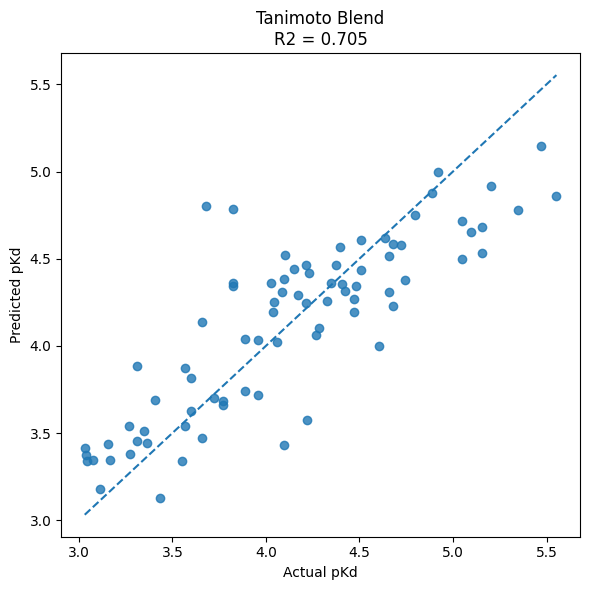

In [29]:

mean_oof = random_oof.mean(axis=0)

plt.figure(figsize=(6, 6))

plt.scatter(y, mean_oof, alpha=0.8)

low = min(y.min(), mean_oof.min())
high = max(y.max(), mean_oof.max())

plt.plot([low, high], [low, high], "--")

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")

plt.title(
    f"Tanimoto Blend\nR2 = {r2_score(y, mean_oof):.3f}"
)

plt.tight_layout()
plt.show()


In [30]:

os.makedirs("USP5_Tanimoto_Results", exist_ok=True)

random_results.to_csv(
    "USP5_Tanimoto_Results/Random_5Fold_Results.csv",
    index=False
)

scaffold_results.to_csv(
    "USP5_Tanimoto_Results/Scaffold_5Fold_Results.csv",
    index=False
)

oof_df = df[
    ["Molecule ChEMBL ID", "Smiles", "pKd"]
].copy()

for i in range(random_oof.shape[0]):
    oof_df[f"Repeat_{i+1}_Prediction"] = random_oof[i]

oof_df["Mean_Prediction"] = mean_oof

oof_df.to_csv(
    "USP5_Tanimoto_Results/Random_5Fold_OOF.csv",
    index=False
)

print("All results saved!")


All results saved!


In [ ]:

from google.colab import files
import shutil

shutil.make_archive(
    "USP5_Tanimoto_Results",
    "zip",
    "USP5_Tanimoto_Results"
)

files.download("USP5_Tanimoto_Results.zip")
